# 04b — Validación de supuestos: modelo de panel (efectos fijos de dos vías)

**Proyecto:** Análisis de Elasticidad de Demanda en Delivery de Comida (v2)
**Fase:** 4b — Validación del modelo de la Fase 3b (elasticidad = -1.5985)

Objetivos:
1. Inspección de residuos del modelo de panel (normalidad, Q-Q plot)
2. Verificar que los errores clusterizados sean apropiados (comparar
   contra errores no clusterizados, para dimensionar el impacto)
3. Discusión de limitaciones específicas del modelo de panel (identidad
   de qué SÍ y qué NO controla el estimador *within*)


In [1]:
import sys
sys.path.append('../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

from modeling import modelo_panel_efectos_fijos
pd.set_option('display.max_columns', None)

## 1. Cargar datos y reajustar el modelo de panel

In [2]:
df = pd.read_csv('../data/processed/demanda_limpia.csv')
resultado_panel = modelo_panel_efectos_fijos(df)
print('Modelo reajustado. Elasticidad:', resultado_panel.params['log_checkout_price'])

Modelo reajustado. Elasticidad: -1.5985291480156163


## 2. Residuos del modelo de panel

`linearmodels` expone los residuos en `.resids` (no `.resid` como
statsmodels).

In [3]:
residuos_panel = resultado_panel.resids
print(f'N residuos: {len(residuos_panel)}')
print(f'Media: {residuos_panel.mean():.6f} (debería ser ≈0)')
print(f'Desv. est.: {residuos_panel.std():.4f}')

N residuos: 456548
Media: 0.000000 (debería ser ≈0)
Desv. est.: 0.5147


## 3. Q-Q plot de los residuos del modelo de panel

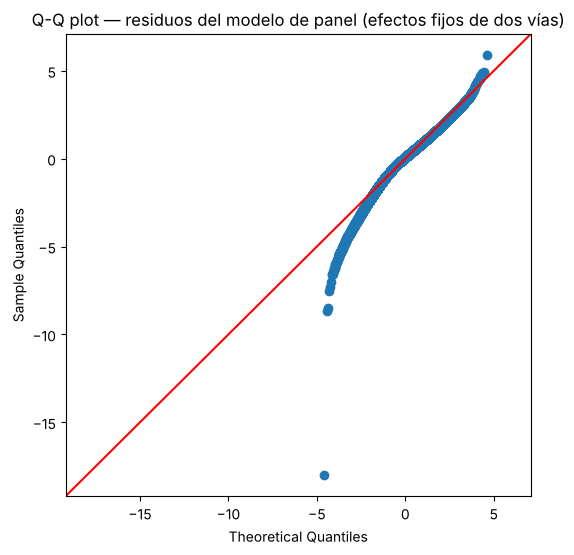

In [4]:
fig = sm.qqplot(np.asarray(residuos_panel), line='45', fit=True)
fig.set_size_inches(6, 6)
plt.title('Q-Q plot — residuos del modelo de panel (efectos fijos de dos vías)')
plt.savefig('../reports/notebook_outputs/qq_panel_fe.png', dpi=150, bbox_inches='tight')
plt.show()

**Nota de comparación:** el Shapiro-Wilk submuestreado ya se corrió en
el notebook 03b (estadístico≈0.983, p<0.001). Aquí se complementa con la
inspección visual del Q-Q plot, igual que se hizo para el modelo OLS en
la Fase 4 original.

## 4. Dimensionar el impacto del clustering en los errores estándar

Se reajusta el mismo modelo SIN clusterizar (errores robustos estándar),
para comparar contra la versión clusterizada por entidad y ver cuánto
cambia la inferencia.

In [5]:
from linearmodels import PanelOLS
from modeling import preparar_panel

df_panel = preparar_panel(df)
formula = (
    'log_num_orders ~ log_checkout_price + emailer_for_promotion '
    '+ homepage_featured + EntityEffects + TimeEffects'
)
modelo_sin_cluster = PanelOLS.from_formula(formula, data=df_panel)
resultado_sin_cluster = modelo_sin_cluster.fit(cov_type='robust')

ee_clusterizado = resultado_panel.std_errors['log_checkout_price']
ee_robusto_simple = resultado_sin_cluster.std_errors['log_checkout_price']

print(f'Error estándar clusterizado (por entidad): {ee_clusterizado:.5f}')
print(f'Error estándar robusto (sin clusterizar):  {ee_robusto_simple:.5f}')
print(f'Ratio clusterizado/robusto: {ee_clusterizado/ee_robusto_simple:.2f}')

Error estándar clusterizado (por entidad): 0.02391
Error estándar robusto (sin clusterizar):  0.01139
Ratio clusterizado/robusto: 2.10


**Interpretación esperada:** si el error estándar clusterizado es
notablemente mayor que el robusto simple, confirma que ignorar la
dependencia dentro de cada entidad (centro-comida) habría producido
intervalos de confianza artificialmente angostos -- justifica la
decisión de clusterizar.

## 5. Limitaciones específicas del modelo de panel

- **Qué SÍ controla:** heterogeneidad no observada constante en el tiempo
  para cada combinación centro-comida (calidad percibida, ubicación,
  preferencias locales fijas), y shocks agregados que afectan a todas las
  entidades por igual en una semana dada (estacionalidad, tendencia de
  la plataforma)
- **Qué NO controla:** simultaneidad precio-demanda (si el centro sube el
  precio *en respuesta* a un shock de demanda esa misma semana, el
  estimador *within* sigue sesgado) -- ese problema es el que aborda la
  Fase 3c (IV), no este modelo
- **Solo usa variación dentro de cada entidad:** combinaciones centro-comida
  con pocas semanas de datos (ver Min Obs=1 en el resumen del modelo,
  notebook 03b) aportan poca o ninguna variación *within*, y su
  contribución a la estimación es limitada aunque sigan en la muestra